# IEEE System in Python

We provide the implementation of the PF model. For simplicity and demonstration considerations, we choose DC OPF formulation. We start by defining the custom model and confirm it against the commercial package of PyPSA.

Setting up the necessary packages and environment:

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Compute/
!pip -q install cvxpy highspy matpowercaseframes pypsa

import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt, cvxpy as cp
print(cp.installed_solvers())

Mounted at /content/drive
/content/drive/MyDrive/Compute
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


['CLARABEL', 'CVXOPT', 'GLPK', 'GLPK_MI', 'HIGHS', 'OSQP', 'SCIPY', 'SCS']


We download the IEEE 30-bus system of the Alsac-Stott version. We construct the necessary variables.

In [2]:
# case30_as has 6 generators with rising quadratic costs
!wget -q -nc https://raw.githubusercontent.com/power-grid-lib/pglib-opf/master/pglib_opf_case30_as.m
from matpowercaseframes import CaseFrames
cf = CaseFrames('pglib_opf_case30_as.m')
bus, br, gen, gc = cf.bus, cf.branch, cf.gen, cf.gencost
nb, nl, ng = len(bus), len(br), len(gen)

BUS_I   = bus.BUS_I.astype(int).values           # bus numbers (1..30)
F_BUS   = br.F_BUS.astype(int).values            # line from-bus (number)
T_BUS   = br.T_BUS.astype(int).values            # line to-bus (number)
GEN_BUS = gen.GEN_BUS.astype(int).values         # generator bus (number)

bidx = {b: i for i, b in enumerate(BUS_I)}       # bus number -> row index
fb = np.array([bidx[b] for b in F_BUS])          # line from-bus (row index)
tb = np.array([bidx[b] for b in T_BUS])          # line to-bus (row index)
gb = np.array([bidx[b] for b in GEN_BUS])        # generator bus (row index)

pd0  = bus.PD.values                             # load per bus (MW)
RATE = br.RATE_A.values.copy()                   # line limits (MW)
pmin, pmax = gen.PMIN.values, gen.PMAX.values    # generator limits (MW)
print(f'{nb} buses, {nl} lines, {ng} gens, load {pd0.sum():.0f} MW, gen cap {pmax.sum():.0f} MW')
print(pd.DataFrame({'bus': GEN_BUS, 'Pmin': pmin, 'Pmax': pmax}))

30 buses, 41 lines, 6 gens, load 283 MW, gen cap 435 MW
   bus  Pmin   Pmax
0    1  50.0  200.0
1    2  20.0   80.0
2    5  15.0   50.0
3    8  10.0   35.0
4   11  10.0   30.0
5   13  12.0   40.0


We know construct the Power Transfer Distribution Factor (PTDF) formulation of the DC OPF.

### PTDF formulation of the DC OPF: equation by equation

**Notation.** $n_b, n_l, n_g$ are the numbers of buses, branches and generators. Branch $l$ goes from bus $f(l)$ to bus $t(l)$, with series reactance $x_l$ (p.u.) and off-nominal tap ratio $\tau_l$. Bus 1 (row 0) is the reference bus.

---

**(1) Tap convention**

$$\tau_l = \begin{cases} \text{TAP}_l & \text{if } \text{TAP}_l \neq 0 \\ 1 & \text{if } \text{TAP}_l = 0 \end{cases}$$

In the MATPOWER case format, column 9 (`TAP`) is the transformer off-nominal turns ratio, and a value of 0 marks a plain transmission line. The tap sits at the *from* bus [2, App. B / `caseformat.m`]. Setting $\tau_l = 1$ for these lines makes the branch model below reduce to an ordinary line.

**(2) Branch susceptance (with tap)**

$$b_l = \frac{1}{x_l\,\tau_l}$$

Source: [2, Sec. 3.7, definition of $b_i$ following eq. (3.24)].

Why: MATPOWER models every branch as a $\pi$-line in series with an ideal phase-shifting transformer of ratio $\tau$ at the from end [2, Sec. 3.2, eq. (3.2)]. Three assumptions are then applied [2, eqs. (3.18)–(3.20)]:
- the branch is lossless ($r_s \approx 0$, $b_c \approx 0$),
- voltage magnitudes are about 1 p.u.,
- angle differences are small.

Under these, the active flow through the transformer-plus-line reduces to $b_l(\theta_f-\theta_t)$ with $b_l = 1/(x_l\tau_l)$ [2, eqs. (3.21)–(3.24)].

For $\tau_l = 1$ this is the textbook $P_{ij} = (\delta_i-\delta_j)/x_{ij}$ [1, eq. (3.2)]. Note that $b_l = 1/x_l$ here, not $\mathrm{Im}\{1/z_l\}$ [1, Sec. 3.7, "B in DC-OPF vs Y in AC-OPF"].

**(3) Branch–bus incidence matrix**

$$A = C_f - C_t \in \{-1,0,1\}^{n_l\times n_b}, \qquad A_{l,f(l)} = +1,\; A_{l,t(l)} = -1$$

$C_f$ and $C_t$ are MATPOWER's from-bus and to-bus connection matrices [2, Sec. 3.2]. $A$ enters the DC matrices through the difference $C_f - C_t$ [2, eqs. (3.30)–(3.31)].

**(4) Branch flows as a function of bus angles**

$$f = B_f\,\theta, \qquad B_f = \mathrm{diag}(b)\,A$$

Source: [2, eqs. (3.29)–(3.30)], with the phase-shift term $P_{f,\text{shift}} = 0$.

This is the same object as the "line susceptance matrix" $\mathbf{B}_{\text{line}}$ in [1, eq. (3.16)]: each row has $+b_l$ at the from bus and $-b_l$ at the to bus.

**(5) Bus susceptance matrix**

$$B_{\text{bus}} = A^\top \mathrm{diag}(b)\,A$$

Source: [2, eq. (3.31)]. It is equivalent to the element-by-element rules in [1, Sec. 3.4.1]: diagonal entries are $\sum_k b_{ik}$, and off-diagonal entries are $-b_{ij}$.

**(6) Nodal power balance**

$$B_{\text{bus}}\,\theta = p, \qquad p = C_g P_g - P_d$$

Source: [2, eq. (3.32)], with shunts $G_{sh} = 0$ and $P_{\text{bus,shift}} = 0$; also [1, eqs. (3.6), (3.8)].

$C_g\in\{0,1\}^{n_b\times n_g}$ maps generators to their buses [2, Sec. 3.3 and eq. (3.32)]. This is `Cg` in the code.

**(7) Reduced inverse ("bus reactance matrix")**

$B_{\text{bus}}$ is singular, so we:
1. remove the reference row and column, giving $\tilde B_{\text{bus}}$;
2. invert it;
3. re-insert a zero row and column at the reference bus.

$$X = \begin{bmatrix} 0 & 0 \\ 0 & \tilde B_{\text{bus}}^{-1}\end{bmatrix}$$

Source: [1, Sec. 3.8.1, steps 1–3]. MATPOWER does the same elimination of the reference-bus column [2, Sec. 4, PTDF definition; eq. (4.36) in v7.1].

**(8) PTDF matrix**

$$H = \mathrm{diag}(b)\,A\,X = B_f\,X$$

Source: [1, eqs. (3.15), (3.19)] and [2, $\tilde H = \tilde B_f B_{dc}^{-1}$].

$H_{l,n}$ is the change in flow on line $l$ when 1 MW is injected at bus $n$ and withdrawn at the reference bus [1, eq. (3.11)]. Therefore $H_{l,\text{ref}} = 0$.

**(9) Flows from injections**

$$f = H\,p$$

Source: [1, eqs. (3.13), (3.17)–(3.20)].

This only holds for balanced injections ($\mathbf 1^\top p = 0$). In that case the flows do not depend on which bus is chosen as reference, because only differences of PTDF columns matter [1, eq. (3.12)].

**(10) DC-OPF in PTDF form** (per hour $t$)

$$\min_{P_g}\; \sum_g c_g(P_g)$$

subject to

$$\mathbf 1^\top (C_g P_g - P_d) = 0 \qquad (\nu)$$
$$H\,(C_g P_g - P_d) \le \bar f \qquad (\kappa^+)$$
$$-H\,(C_g P_g - P_d) \le \bar f \qquad (\kappa^-)$$
$$P_g^{\min} \le P_g \le P_g^{\max}$$

Source: [1, Sec. 3.9, eqs. (3.21)–(3.23)]. One system-wide balance equation replaces the $n_b$ nodal balances [1, Sec. 3.9]. (The piecewise-linear cost $c_g$ is documented in the cost cell.)

**(11) Locational marginal prices**

$$\text{LMP}_n = \nu_{\text{ref}} - \sum_l (\kappa_l^+ - \kappa_l^-)\,H_{l,n}$$

Source: obtained from the Lagrangian in [1, App. A], where $\text{LMP}_i = -\nu - \lambda^+_{13}\,\text{PTDF}_{13,i}$, extended to all lines and both flow directions.

The first term is the energy price at the reference bus. The sum is the congestion component. The *split* depends on the reference bus, but the LMP itself does not [3].

The sign of $\nu_{\text{ref}}$ follows from CVXPY's dual convention. It is checked numerically by the `assert` and by the PyPSA comparison.

**Units remark.** We use MW with $b = 1/x$ in p.u. reactance. $H$ is unchanged if all $b_l$ are scaled by a common factor, so the PTDF is unaffected. Only the implicit angles $\theta$ lose their physical meaning in radians [1, Sec. 3.7, "If δ is in rad, then P is in per unit"].

---

**References**

[1] S. Chatzivasileiadis, *Optimization in Modern Power Systems*, DTU Course 31765 Lecture Notes, arXiv:1811.00943, 2018.

[2] R. D. Zimmerman, C. E. Murillo-Sánchez, *MATPOWER User's Manual*, v8.1, PSERC (https://matpower.org/docs/MATPOWER-manual.pdf); data format in `caseformat.m`. Software citation: R. D. Zimmerman, C. E. Murillo-Sánchez, R. J. Thomas, "MATPOWER: Steady-State Operations, Planning, and Analysis Tools for Power Systems Research and Education," *IEEE Trans. Power Syst.*, 26(1):12–19, 2011.

[3] E. Litvinov, T. Zheng, G. Rosenwald, P. Shamsollahi, "Marginal Loss Modeling in LMP Calculation," *IEEE Trans. Power Syst.*, 19(2), 2004, doi:10.1109/TPWRS.2004.825894.

In [3]:
# Injections are withdrawn at bus 1 (row 0), the reference bus.
tap = br.TAP.values.copy(); tap[tap == 0] = 1
b_line = 1 / (br.BR_X.values * tap)              # line susceptance

A = np.zeros((nl, nb))                           # incidence matrix: +1 at from-bus, -1 at to-bus
A[np.arange(nl), fb] = 1
A[np.arange(nl), tb] = -1

Bbus = A.T @ np.diag(b_line) @ A                 # bus susceptance matrix
X = np.zeros((nb, nb))
X[1:, 1:] = np.linalg.inv(Bbus[1:, 1:])          # drop the reference bus, invert
H = np.diag(b_line) @ A @ X                      # PTDF: flow = H @ net injection

Cg = np.zeros((nb, ng)); Cg[gb, np.arange(ng)] = 1   # generator -> bus map

In [4]:
# quadratic cost c2 p^2 + c1 p + c0, cut into NSEG straight pieces such that the problem stays an LP
COST_SCALE = 15                                  # original costs 2–4 $/MWh -> translate to $30–60/MWh (assumption)
NSEG = 10
c2, c1, c0 = COST_SCALE * gc.iloc[:, 4:7].values.T
breaks = np.linspace(pmin, pmax, NSEG + 1).T     # breakpoints [gen, NSEG+1]
cost_at_breaks = c2[:, None] * breaks**2 + c1[:, None] * breaks + c0[:, None]
wid   = np.diff(breaks, axis=1)                  # MW width of each piece
slope = np.diff(cost_at_breaks, axis=1) / wid    # $/MWh of each piece (rising -> convex)

LOAD_SHAPE = np.array([.62,.58,.56,.55,.57,.63,.72,.82,.88,.92,.95,.97,
                       .98,.99,1.0,1.0,.99,.97,.95,.92,.87,.80,.72,.66])   # placeholder assumed load
Dgrid = LOAD_SHAPE[:, None] * pd0[None]          # MW [hour, bus]
PK = LOAD_SHAPE.argmax()                         # peak hour
T = 24

In [5]:
# %% 4. Grid-only DC-OPF (24 h, no ramps so it can be compared with PyPSA) ---------
g    = cp.Variable((T, ng, NSEG), nonneg=True)   # MW used in each cost piece
Pg   = pmin + cp.sum(g, axis=2)                  # generator output [hour, gen]
inj  = Pg @ Cg.T - Dgrid                         # net injection per bus
flow = inj @ H.T                                 # line flows

balance = cp.sum(inj, axis=1) == 0               # system power balance  -> ν_ref
line_up = flow <= RATE                           # line limits           -> κ+
line_lo = -flow <= RATE                          #                       -> κ-
cost    = cp.sum(cp.multiply(g, slope[None]))

prob = cp.Problem(cp.Minimize(cost), [balance, line_up, line_lo, g <= wid[None]])
prob.solve(solver=cp.HIGHS)

nu_ref = -balance.dual_value                                            # $/MWh at the reference bus
LMP    = nu_ref[:, None] - (line_up.dual_value - line_lo.dual_value) @ H   # $/MWh [hour, bus]
P_opf, F_opf = Pg.value, flow.value
assert nu_ref.mean() > 0, 'dual sign flipped'

print('reference price by hour:', nu_ref.round(1))
print('LMP spread by hour:', np.ptp(LMP, axis=1).round(2))      # should be 0 as no congestion without data centers
print('peak line loading (top 5):', np.sort(np.abs(F_opf[PK]) / RATE)[-5:].round(2))

/usr/local/lib/python3.13/dist-packages/cvxpy/reductions/solvers/solving_chain_utils.py:30: UserWarning: The problem includes expressions that don't support CPP backend. Defaulting to the SCIPY backend for canonicalization.
  warnings.warn(UserWarning(


reference price by hour: [41.5 39.8 39.8 39.8 39.8 41.5 44.6 46.6 47.8 48.3 50.  50.  50.  50.9
 50.9 50.9 50.9 50.  50.  48.3 47.8 46.4 44.6 41.5]
LMP spread by hour: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
peak line loading (top 5): [0.56 0.62 0.65 0.76 0.95]


In [6]:

import pypsa
net = pypsa.Network(); net.set_snapshots(range(T))
buses = [f'b{i}' for i in range(nb)]
lines = [f'l{l}' for l in range(nl)]
loads = [f'd{i}' for i in range(nb)]

net.add('Bus', buses, v_nom=1.0)
net.add('Line', lines, bus0=[buses[i] for i in fb], bus1=[buses[j] for j in tb],
        x=br.BR_X.values * tap, r=0.0, s_nom=RATE)                 # same susceptance as H
net.add('Load', loads, bus=buses, p_set=pd.DataFrame(Dgrid, index=net.snapshots, columns=loads))
for i in range(ng):
    if pmin[i] > 0:                                                 # must-run block at Pmin
        net.add('Generator', f'g{i}_min', bus=buses[gb[i]], p_nom=pmin[i], p_min_pu=1.0)
    for j in range(NSEG):                                           # one generator per cost piece
        net.add('Generator', f'g{i}_{j}', bus=buses[gb[i]], p_nom=wid[i, j], marginal_cost=slope[i, j])
net.optimize(solver_name='highs')

# PTDF from PyPSA, re-referenced to our reference bus (row 0)
sn = net.sub_networks.obj.iloc[0]; sn.calculate_PTDF()
H_pypsa = pd.DataFrame(sn.PTDF, index=sn.branches_i().get_level_values(-1),
                       columns=sn.buses_o).loc[lines, buses].values
H_pypsa = H_pypsa - H_pypsa[:, [0]]

P_pypsa = np.column_stack([net.generators_t.p.filter(regex=rf'^g{i}_').sum(axis=1) for i in range(ng)])
print('max PTDF difference:        ', np.abs(H_pypsa - H).max().round(6))
print('max generator diff (MW):    ', np.abs(P_pypsa - P_opf).max().round(4))
print('max flow diff (MW):         ', np.abs(net.lines_t.p0[lines].values - F_opf).max().round(4))
print('max LMP diff ($/MWh):       ', np.abs(net.buses_t.marginal_price[buses].values - LMP).max().round(4))

/usr/local/lib/python3.13/dist-packages/pypsa/network/io.py:2079: FutureWarning:

pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.

/tmp/ipykernel_841/567630456.py:16: FutureWarning:

The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.

Index(['b0', 'b1', 'b2', 'b3', 'b4', 'b5', 'b6', 'b7', 'b8', 'b9', 'b10',
       'b11', 'b12', 'b13', 'b14', 'b15', 'b16', 'b17', 'b18', 'b19', 'b20',
       'b21', 'b22', 'b23', 'b24', 'b25', 'b26', 'b27', 'b28', 'b29'],
      dtype='object', name='name')
Index(['l0', 'l1', 'l2', 'l3', 'l4', 'l5', 'l6', 'l7', 'l8', 'l9', 'l10',
       'l11', 'l

max PTDF difference:         0.0
max generator diff (MW):     0.0
max flow diff (MW):          0.0
max LMP diff ($/MWh):        0.0


In [7]:
#save the grid for the PuttingTogether notebook
SITE_BUS = [3, 8, 21]                            # data center sites (bus numbers)
np.savez('ieee30_grid.npz', BUS_I=BUS_I, F_BUS=F_BUS, T_BUS=T_BUS, GEN_BUS=GEN_BUS,
         H=H, Cg=Cg, pmin=pmin, pmax=pmax, wid=wid, slope=slope, RATE=RATE,
         Dgrid=Dgrid, pd0=pd0, SITE_BUS=np.array(SITE_BUS))

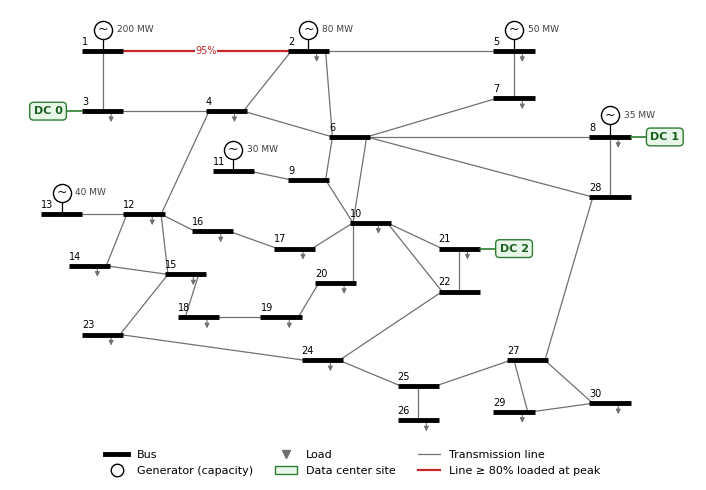

In [8]:
# %% 7. Paper figure: one-line diagram of the 30-bus system ----------------------------------
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Bus positions (x, y), laid out like the usual one-line diagram (buses 1–8, 28 on top)
POS = {1:(0.0,6.0),  2:(3.0,6.0),  5:(6.0,6.0),
       3:(0.0,4.6),  4:(1.8,4.6),  7:(6.0,4.9),
       6:(3.6,4.0),  8:(7.4,4.0),  9:(3.0,3.0),  11:(1.9,3.2), 28:(7.4,2.6),
       12:(0.6,2.2), 13:(-0.6,2.2), 10:(3.9,2.0), 16:(1.6,1.8), 17:(2.8,1.4), 21:(5.2,1.4),
       14:(-0.2,1.0), 15:(1.2,0.8), 20:(3.4,0.6), 22:(5.2,0.4),
       18:(1.4,-0.2), 19:(2.6,-0.2), 23:(0.0,-0.6), 24:(3.2,-1.2), 27:(6.2,-1.2),
       25:(4.6,-1.8), 26:(4.6,-2.6), 29:(6.0,-2.4), 30:(7.4,-2.2)}
HALF       = 0.3                                          # half-length of a bus bar
GEN_OFFSET = {22: (0.65, 0.0), 27: (0.65, 0.0)}           # generator symbol position if not above the bar
DC_OFFSET  = {3: (-0.8, 0.0), 8: (0.8, 0.0), 21: (0.8, 0.0)}   # data center box position
HOT        = 0.8                                          # highlight lines loaded above this share

loading = np.abs(F_opf[PK]) / RATE                        # peak-hour loading, share of rating
fig, ax = plt.subplots(figsize=(7.16, 5.0))

# Lines: each end attaches to the point of its bus bar closest to the other bus
for l in range(nl):
    (xa, ya), (xb, yb) = POS[F_BUS[l]], POS[T_BUS[l]]
    x0 = np.clip(xb, xa - HALF + 0.05, xa + HALF - 0.05)
    x1 = np.clip(xa, xb - HALF + 0.05, xb + HALF - 0.05)
    hot = loading[l] >= HOT
    ax.plot([x0, x1], [ya, yb], color='#c62828' if hot else '#707070', lw=1.6 if hot else 0.9, zorder=1)
    if hot:
        ax.text((x0 + x1) / 2, (ya + yb) / 2, f'{loading[l]:.0%}', fontsize=7, color='#c62828',
                ha='center', va='center', bbox=dict(fc='white', ec='none', pad=0.3), zorder=3)

# Bus bars and bus numbers
for b in BUS_I:
    bx, by = POS[b]
    ax.plot([bx - HALF, bx + HALF], [by, by], color='k', lw=3.5, solid_capstyle='butt', zorder=2)
    ax.text(bx - HALF, by + 0.1, str(b), fontsize=7, ha='left', va='bottom', zorder=4)

# Loads: small arrow below the bar
for i, b in enumerate(BUS_I):
    if pd0[i] > 0:
        bx, by = POS[b]
        ax.annotate('', xy=(bx + 0.12, by - 0.32), xytext=(bx + 0.12, by), zorder=1,
                    arrowprops=dict(arrowstyle='-|>', color='#707070', lw=0.8, mutation_scale=7))

# Generators: circle with "~" on a short stub, capacity next to it
for i, b in enumerate(GEN_BUS):
    bx, by = POS[b]
    dx, dy = GEN_OFFSET.get(b, (0.0, 0.5))
    gx, gy = bx + dx, by + dy
    ax.plot([bx + np.clip(dx, -HALF, HALF), gx], [by, gy], color='k', lw=0.9, zorder=2)
    ax.scatter(gx, gy, s=170, facecolor='white', edgecolor='k', lw=1.0, zorder=3)
    ax.text(gx, gy, '~', ha='center', va='center', fontsize=9, zorder=4)
    ax.text(gx + 0.2, gy, f'{pmax[i]:.0f} MW', fontsize=6.5, color='#404040', va='center', zorder=4)

# Data center sites: labeled box on a short stub
for s, b in enumerate(SITE_BUS):
    bx, by = POS[b]
    dx, dy = DC_OFFSET.get(b, (0.0, -0.6))
    ax.plot([bx + np.clip(dx, -HALF, HALF), bx + dx], [by, by + dy], color='#2e7d32', lw=1.2, zorder=2)
    ax.text(bx + dx, by + dy, f'DC {s}', ha='center', va='center', fontsize=8, fontweight='bold',
            color='#1b5e20', bbox=dict(boxstyle='round,pad=0.35', fc='#e8f5e9', ec='#2e7d32', lw=1.0), zorder=4)

ax.legend(handles=[
    Line2D([], [], color='k', lw=3.5, label='Bus'),
    Line2D([], [], marker='o', ls='', mfc='white', mec='k', ms=9, label='Generator (capacity)'),
    Line2D([], [], marker='v', ls='', color='#707070', ms=6, label='Load'),
    Patch(fc='#e8f5e9', ec='#2e7d32', label='Data center site'),
    Line2D([], [], color='#707070', lw=0.9, label='Transmission line'),
    Line2D([], [], color='#c62828', lw=1.6, label=f'Line ≥ {HOT:.0%} loaded at peak')],
    loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False, fontsize=8)
ax.axis('off')
plt.tight_layout(); plt.savefig('fig_ieee30.pdf', bbox_inches='tight'); plt.show()

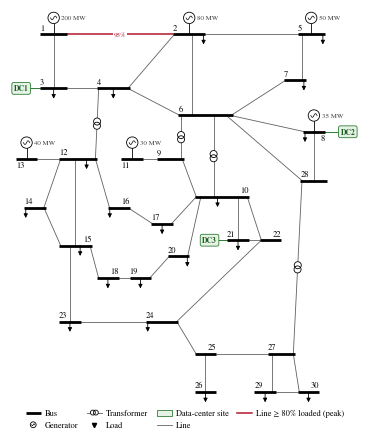

In [9]:
# %% 7. Paper figure: IEEE 30-bus one-line diagram (classic layout) ---------------------------
from collections import defaultdict
from matplotlib.patches import Circle, Patch
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerBase

# ---------------- style ----------------
FIG_W    = 3.5                     # inches: 3.5 = IEEE single column, 7.16 = double column
FS_BUS   = 6.0                     # bus numbers / legend
FS_SMALL = 5.0                     # capacities, loadings, DC labels
INK, GREY, HOTC = 'k', '#606060', '#b2182b'
DC_FC, DC_EC, DC_TXT = '#e6f2e6', '#2e7d32', '#1b5e20'
HOT   = 0.8                        # highlight lines loaded at/above this share at peak
LEG_H = 0.42                       # inches reserved for the legend below the diagram
plt.rcParams.update({'font.family': 'serif',
                     'font.serif': ['Times New Roman', 'Times', 'Nimbus Roman', 'STIXGeneral', 'DejaVu Serif'],
                     'mathtext.fontset': 'stix', 'pdf.fonttype': 42, 'ps.fonttype': 42})

# ---------------- layout (classic IEEE 30-bus drawing; x right, y up) ----------------
POS = {1:(0.0, 9.0),  2:(5.0, 9.0),  5:(9.5, 9.0),
       3:(0.0, 7.0),  4:(2.2, 7.0),  7:(8.9, 7.3),
       6:(5.6, 6.0),  8:(9.6, 5.4),
       13:(-1.0, 4.4), 12:(0.9, 4.4), 11:(2.9, 4.4), 9:(4.3, 4.4), 28:(9.6, 3.6),
       10:(6.2, 3.0),
       14:(-0.7, 2.6), 16:(2.4, 2.6), 17:(4.0, 2.0),
       15:(0.8, 1.2), 21:(6.8, 1.4), 22:(8.0, 1.4),
       20:(4.6, 0.8), 18:(2.0, 0.0), 19:(3.2, 0.0),
       23:(0.6, -1.6), 24:(4.0, -1.6),
       25:(5.6, -2.8), 27:(8.4, -2.8),
       26:(5.6, -4.2), 29:(7.8, -4.2), 30:(9.4, -4.2)}
H0   = 0.4                                             # default half-length of a bus bar
HALF = {1:.5, 2:.6, 3:.5, 4:.6, 5:.5, 6:1.0, 9:.5, 10:1.0, 12:.7, 15:.6, 24:.6, 27:.5, 28:.5}
GEN_DIR   = {}                                         # 'up' (default) / 'down' / 'left' / 'right'
DC_OFFSET = {3: (-1.2, 0.0), 8: (1.25, 0.0), 21: (-1.05, 0.0)}   # data-center box offset from bus
DC_LABEL  = [f'DC{s + 1}' for s in range(len(SITE_BUS))]         # 1-based for the paper
LABEL_FIX = {}                                         # force a bus-number spot, e.g. {6: 'br'}

# transformer branches of the original IEEE case (the AS data may carry no tap ratios)
XFMR = {(6, 9), (6, 10), (4, 12), (28, 27)}
XFMR |= {(f, t) for f, t, tp in zip(F_BUS, T_BUS, br.TAP.values) if tp not in (0, 1)}
XFMR = {frozenset(p) for p in XFMR}

def bar(b):
    x, y = POS[b]; h = HALF.get(b, H0)
    return x - h, x + h, y

# data units per inch (used to size text boxes for collision checks)
_lo = min(bar(b)[0] for b in POS); _hi = max(bar(b)[1] for b in POS)
UPI = (_hi - _lo + 1.3) / FIG_W

def text_rect(x, y, s, fs, ha, va):
    hgt = fs / 72 * UPI; wid = 0.55 * hgt * len(s)
    x0 = {'left': x, 'right': x - wid, 'center': x - wid / 2}[ha]
    y0 = {'bottom': y, 'top': y - hgt, 'center': y - hgt / 2}[va]
    return x0, y0, x0 + wid, y0 + hgt

obs = []                                               # sampled points of everything drawn
def add_seg(p, q, step=0.04):
    n = max(2, int(np.hypot(q[0] - p[0], q[1] - p[1]) / step) + 1)
    obs.append(np.linspace(p, q, n))
def add_rect(x0, y0, x1, y1, step=0.05):
    gx, gy = np.meshgrid(np.arange(x0, x1 + step, step), np.arange(y0, y1 + step, step))
    obs.append(np.column_stack([gx.ravel(), gy.ravel()]))

# ---------------- line end points: project onto bars, then spread so ends never coincide ----------------
ends, groups = {}, defaultdict(list)
for l in range(nl):
    a, b = F_BUS[l], T_BUS[l]
    (al, ah, ay), (bl, bh, by) = bar(a), bar(b)
    xa, xb = POS[a][0], POS[b][0]
    if abs(ay - by) < 1e-6:                            # same row: connect facing bar ends
        ends[l, 0], ends[l, 1] = (ah, bl) if xb > xa else (al, bh)
        continue
    lo, hi = max(al, bl), min(ah, bh)
    da, db = ((lo + hi) / 2,) * 2 if lo < hi else (np.clip(xb, al, ah), np.clip(xa, bl, bh))
    dy = abs(by - ay)
    groups[a, 'up' if by > ay else 'dn'].append((da, (xb - xa) / dy, l, 0))
    groups[b, 'up' if ay > by else 'dn'].append((db, (xa - xb) / dy, l, 1))

GAP, MARGIN = 0.17, 0.06
for (b, side), items in groups.items():
    lo, hi, _ = bar(b); lo += MARGIN; hi -= MARGIN
    items.sort(key=lambda t: (t[0], t[1]))             # by position, then fan direction (no crossings)
    p = np.clip([t[0] for t in items], lo, hi).astype(float)
    g = min(GAP, (hi - lo) / max(len(p) - 1, 1))
    for i in range(1, len(p)):            p[i] = max(p[i], p[i - 1] + g)
    p[-1] = min(p[-1], hi)
    for i in range(len(p) - 2, -1, -1):   p[i] = min(p[i], p[i + 1] - g)
    for (_, _, l, w), x in zip(items, p): ends[l, w] = x

# ---------------- draw ----------------
loading = np.abs(F_opf[PK]) / RATE                     # peak-hour loading, share of rating
fig, ax = plt.subplots(figsize=(FIG_W, FIG_W))
seg = {}

for l in range(nl):                                    # lines
    p, q = (ends[l, 0], POS[F_BUS[l]][1]), (ends[l, 1], POS[T_BUS[l]][1])
    seg[l] = (p, q)
    hot = loading[l] >= HOT
    ax.plot(*zip(p, q), color=HOTC if hot else GREY, lw=1.1 if hot else 0.6,
            solid_capstyle='round', zorder=1)
    add_seg(p, q)

R_X = 0.13                                             # transformers: two interlocking circles
for l in range(nl):
    if frozenset((F_BUS[l], T_BUS[l])) not in XFMR: continue
    (x0, y0), (x1, y1) = seg[l]
    L = np.hypot(x1 - x0, y1 - y0); ux, uy = (x1 - x0) / L, (y1 - y0) / L
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    centers = [(cx + s * 0.6 * R_X * ux, cy + s * 0.6 * R_X * uy) for s in (-1, 1)]
    for c in centers: ax.add_patch(Circle(c, R_X, fc='white', ec='none', zorder=3))
    for c in centers: ax.add_patch(Circle(c, R_X, fc='none', ec=INK, lw=0.6, zorder=4))
    add_rect(cx - 1.6 * R_X, cy - 1.6 * R_X, cx + 1.6 * R_X, cy + 1.6 * R_X)

for b in BUS_I:                                        # bus bars
    lo, hi, y = bar(b)
    ax.plot([lo, hi], [y, y], color=INK, lw=2.0, solid_capstyle='butt', zorder=5)
    add_seg((lo, y), (hi, y))

R_G, DY_G = 0.21, 0.6                                  # generators: circle with a sine wave
for b in np.unique(GEN_BUS):
    x, y = POS[b]; h = HALF.get(b, H0); cap = pmax[GEN_BUS == b].sum()
    d = GEN_DIR.get(b, 'up')
    if   d == 'up':    gx, gy = x, y + DY_G;     stub = ((x, y), (x, gy - R_G))
    elif d == 'down':  gx, gy = x, y - DY_G;     stub = ((x, y), (x, gy + R_G))
    elif d == 'left':  gx, gy = x - h - DY_G, y; stub = ((x - h, y), (gx + R_G, y))
    else:              gx, gy = x + h + DY_G, y; stub = ((x + h, y), (gx - R_G, y))
    ax.plot(*zip(*stub), color=INK, lw=0.6, zorder=4); add_seg(*stub)
    ax.add_patch(Circle((gx, gy), R_G, fc='white', ec=INK, lw=0.6, zorder=6))
    t = np.linspace(-1, 1, 40)
    ax.plot(gx + 0.55 * R_G * t, gy + 0.32 * R_G * np.sin(np.pi * t), color=INK, lw=0.5, zorder=7)
    add_rect(gx - R_G, gy - R_G, gx + R_G, gy + R_G)
    s = f'{cap:.0f} MW'
    ax.text(gx + R_G + 0.07, gy, s, fontsize=FS_SMALL, color='#404040', ha='left', va='center', zorder=7)
    add_rect(*text_rect(gx + R_G + 0.07, gy, s, FS_SMALL, 'left', 'center'))

dc_down = defaultdict(list)                            # data-center sites
for s, b in enumerate(SITE_BUS):
    x, y = POS[b]; lo, hi, _ = bar(b); h = HALF.get(b, H0)
    dx, dy = DC_OFFSET.get(b, (0.0, -0.7))
    bx, by = x + dx, y + dy
    sx = hi if dx > h else lo if dx < -h else bx
    ax.plot([sx, bx], [y, by], color=DC_EC, lw=0.7, zorder=2); add_seg((sx, y), (bx, by))
    ax.text(bx, by, DC_LABEL[s], ha='center', va='center', fontsize=FS_SMALL + 0.5, color=DC_TXT,
            fontweight='bold', zorder=8,
            bbox=dict(boxstyle='round,pad=0.25', fc=DC_FC, ec=DC_EC, lw=0.6))
    x0, y0, x1, y1 = text_rect(bx, by, DC_LABEL[s], FS_SMALL + 0.5, 'center', 'center')
    add_rect(x0 - 0.1, y0 - 0.1, x1 + 0.1, y1 + 0.1)
    if dy < 0: dc_down[b].append(sx)

LOAD_LEN = 0.38                                        # loads: arrow below the bar, at the freest spot
for i, b in enumerate(BUS_I):
    if pd0[i] <= 0: continue
    lo, hi, y = bar(b); x = POS[b][0]
    taken = [ends[l, w] for _, _, l, w in groups.get((b, 'dn'), [])] + dc_down[b]
    cand = np.linspace(lo + 0.07, hi - 0.07, 13)
    score = [min([abs(c - t) for t in taken], default=9.0) - 0.02 * abs(c - x) for c in cand]
    c = cand[int(np.argmax(score))]
    ax.annotate('', xy=(c, y - LOAD_LEN), xytext=(c, y), zorder=4,
                arrowprops=dict(arrowstyle='-|>', mutation_scale=6, lw=0.6, color=INK, shrinkA=0, shrinkB=0))
    add_seg((c, y), (c, y - LOAD_LEN))

for l in range(nl):                                    # loading labels on hot lines
    if loading[l] < HOT: continue
    (x0, y0), (x1, y1) = seg[l]
    t = 0.27 if frozenset((F_BUS[l], T_BUS[l])) in XFMR else 0.5
    tx, ty = x0 + t * (x1 - x0), y0 + t * (y1 - y0)
    s = f'{loading[l]:.0%}'
    ax.text(tx, ty, s, fontsize=FS_SMALL, color=HOTC, ha='center', va='center', zorder=9,
            bbox=dict(fc='white', ec='none', pad=0.4))
    add_rect(*text_rect(tx, ty, s, FS_SMALL, 'center', 'center'))

D, PREF = 0.09, ['al', 'ar', 'bl', 'br', 'l', 'r']    # bus numbers: least-cluttered of six spots
for b in BUS_I:
    lo, hi, y = bar(b); s = str(b)
    opts = {'al': (lo, y + D, 'left', 'bottom'), 'ar': (hi, y + D, 'right', 'bottom'),
            'bl': (lo, y - D, 'left', 'top'),    'br': (hi, y - D, 'right', 'top'),
            'l':  (lo - D, y, 'right', 'center'), 'r': (hi + D, y, 'left', 'center')}
    P = np.vstack(obs)
    def hits(k):
        x0, y0, x1, y1 = text_rect(opts[k][0], opts[k][1], s, FS_BUS, opts[k][2], opts[k][3])
        return np.sum((P[:, 0] > x0 - .03) & (P[:, 0] < x1 + .03) & (P[:, 1] > y0 - .03) & (P[:, 1] < y1 + .03))
    k = LABEL_FIX.get(b) or min(PREF, key=lambda k: (hits(k), PREF.index(k)))
    x, yy, ha, va = opts[k]
    ax.text(x, yy, s, fontsize=FS_BUS, ha=ha, va=va, zorder=9)
    add_rect(*text_rect(x, yy, s, FS_BUS, ha, va))

# ---------------- legend ----------------
class _Gen: pass
class _Xf:  pass
class HGen(HandlerBase):
    def create_artists(self, legend, orig, x0, y0, w, h, fs, trans):
        r, cx, cy = 0.5 * h, x0 + w / 2, y0 + h / 2; t = np.linspace(-1, 1, 30)
        return [Circle((cx, cy), r, fc='white', ec=INK, lw=0.6, transform=trans),
                Line2D(cx + 0.55 * r * t, cy + 0.32 * r * np.sin(np.pi * t), color=INK, lw=0.5, transform=trans)]
class HXf(HandlerBase):
    def create_artists(self, legend, orig, x0, y0, w, h, fs, trans):
        r, cx, cy = 0.42 * h, x0 + w / 2, y0 + h / 2
        out = [Line2D([x0, x0 + w], [cy, cy], color=GREY, lw=0.6, transform=trans)]
        out += [Circle((cx + s * 0.6 * r, cy), r, fc='white', ec='none', transform=trans) for s in (-1, 1)]
        out += [Circle((cx + s * 0.6 * r, cy), r, fc='none', ec=INK, lw=0.6, transform=trans) for s in (-1, 1)]
        return out

handles = [Line2D([], [], color=INK, lw=2.0, solid_capstyle='butt'), _Gen(), _Xf(),
           Line2D([], [], marker='v', ls='', color=INK, ms=3),
           Patch(fc=DC_FC, ec=DC_EC, lw=0.6),
           Line2D([], [], color=GREY, lw=0.6), Line2D([], [], color=HOTC, lw=1.1)]
labels = ['Bus', 'Generator', 'Transformer', 'Load', 'Data-center site', 'Line',
          f'Line ≥ {HOT:.0%} loaded (peak)']
ax.legend(handles, labels, handler_map={_Gen: HGen(), _Xf: HXf()}, loc='upper center',
          bbox_to_anchor=(0.5, 0.0), ncol=4, frameon=False, fontsize=FS_BUS,
          handlelength=1.8, handletextpad=0.5, columnspacing=1.0, borderaxespad=0.2)

# ---------------- frame to content, size the figure ----------------
P = np.vstack(obs); m = 0.08
x0, x1 = P[:, 0].min() - m, P[:, 0].max() + m
y0, y1 = P[:, 1].min() - m, P[:, 1].max() + m
ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect('equal'); ax.axis('off')
H = FIG_W * (y1 - y0) / (x1 - x0) + LEG_H
fig.set_size_inches(FIG_W, H); ax.set_position([0, LEG_H / H, 1, 1 - LEG_H / H])
plt.savefig('fig_ieee30.pdf', bbox_inches='tight', pad_inches=0.01)
plt.show()

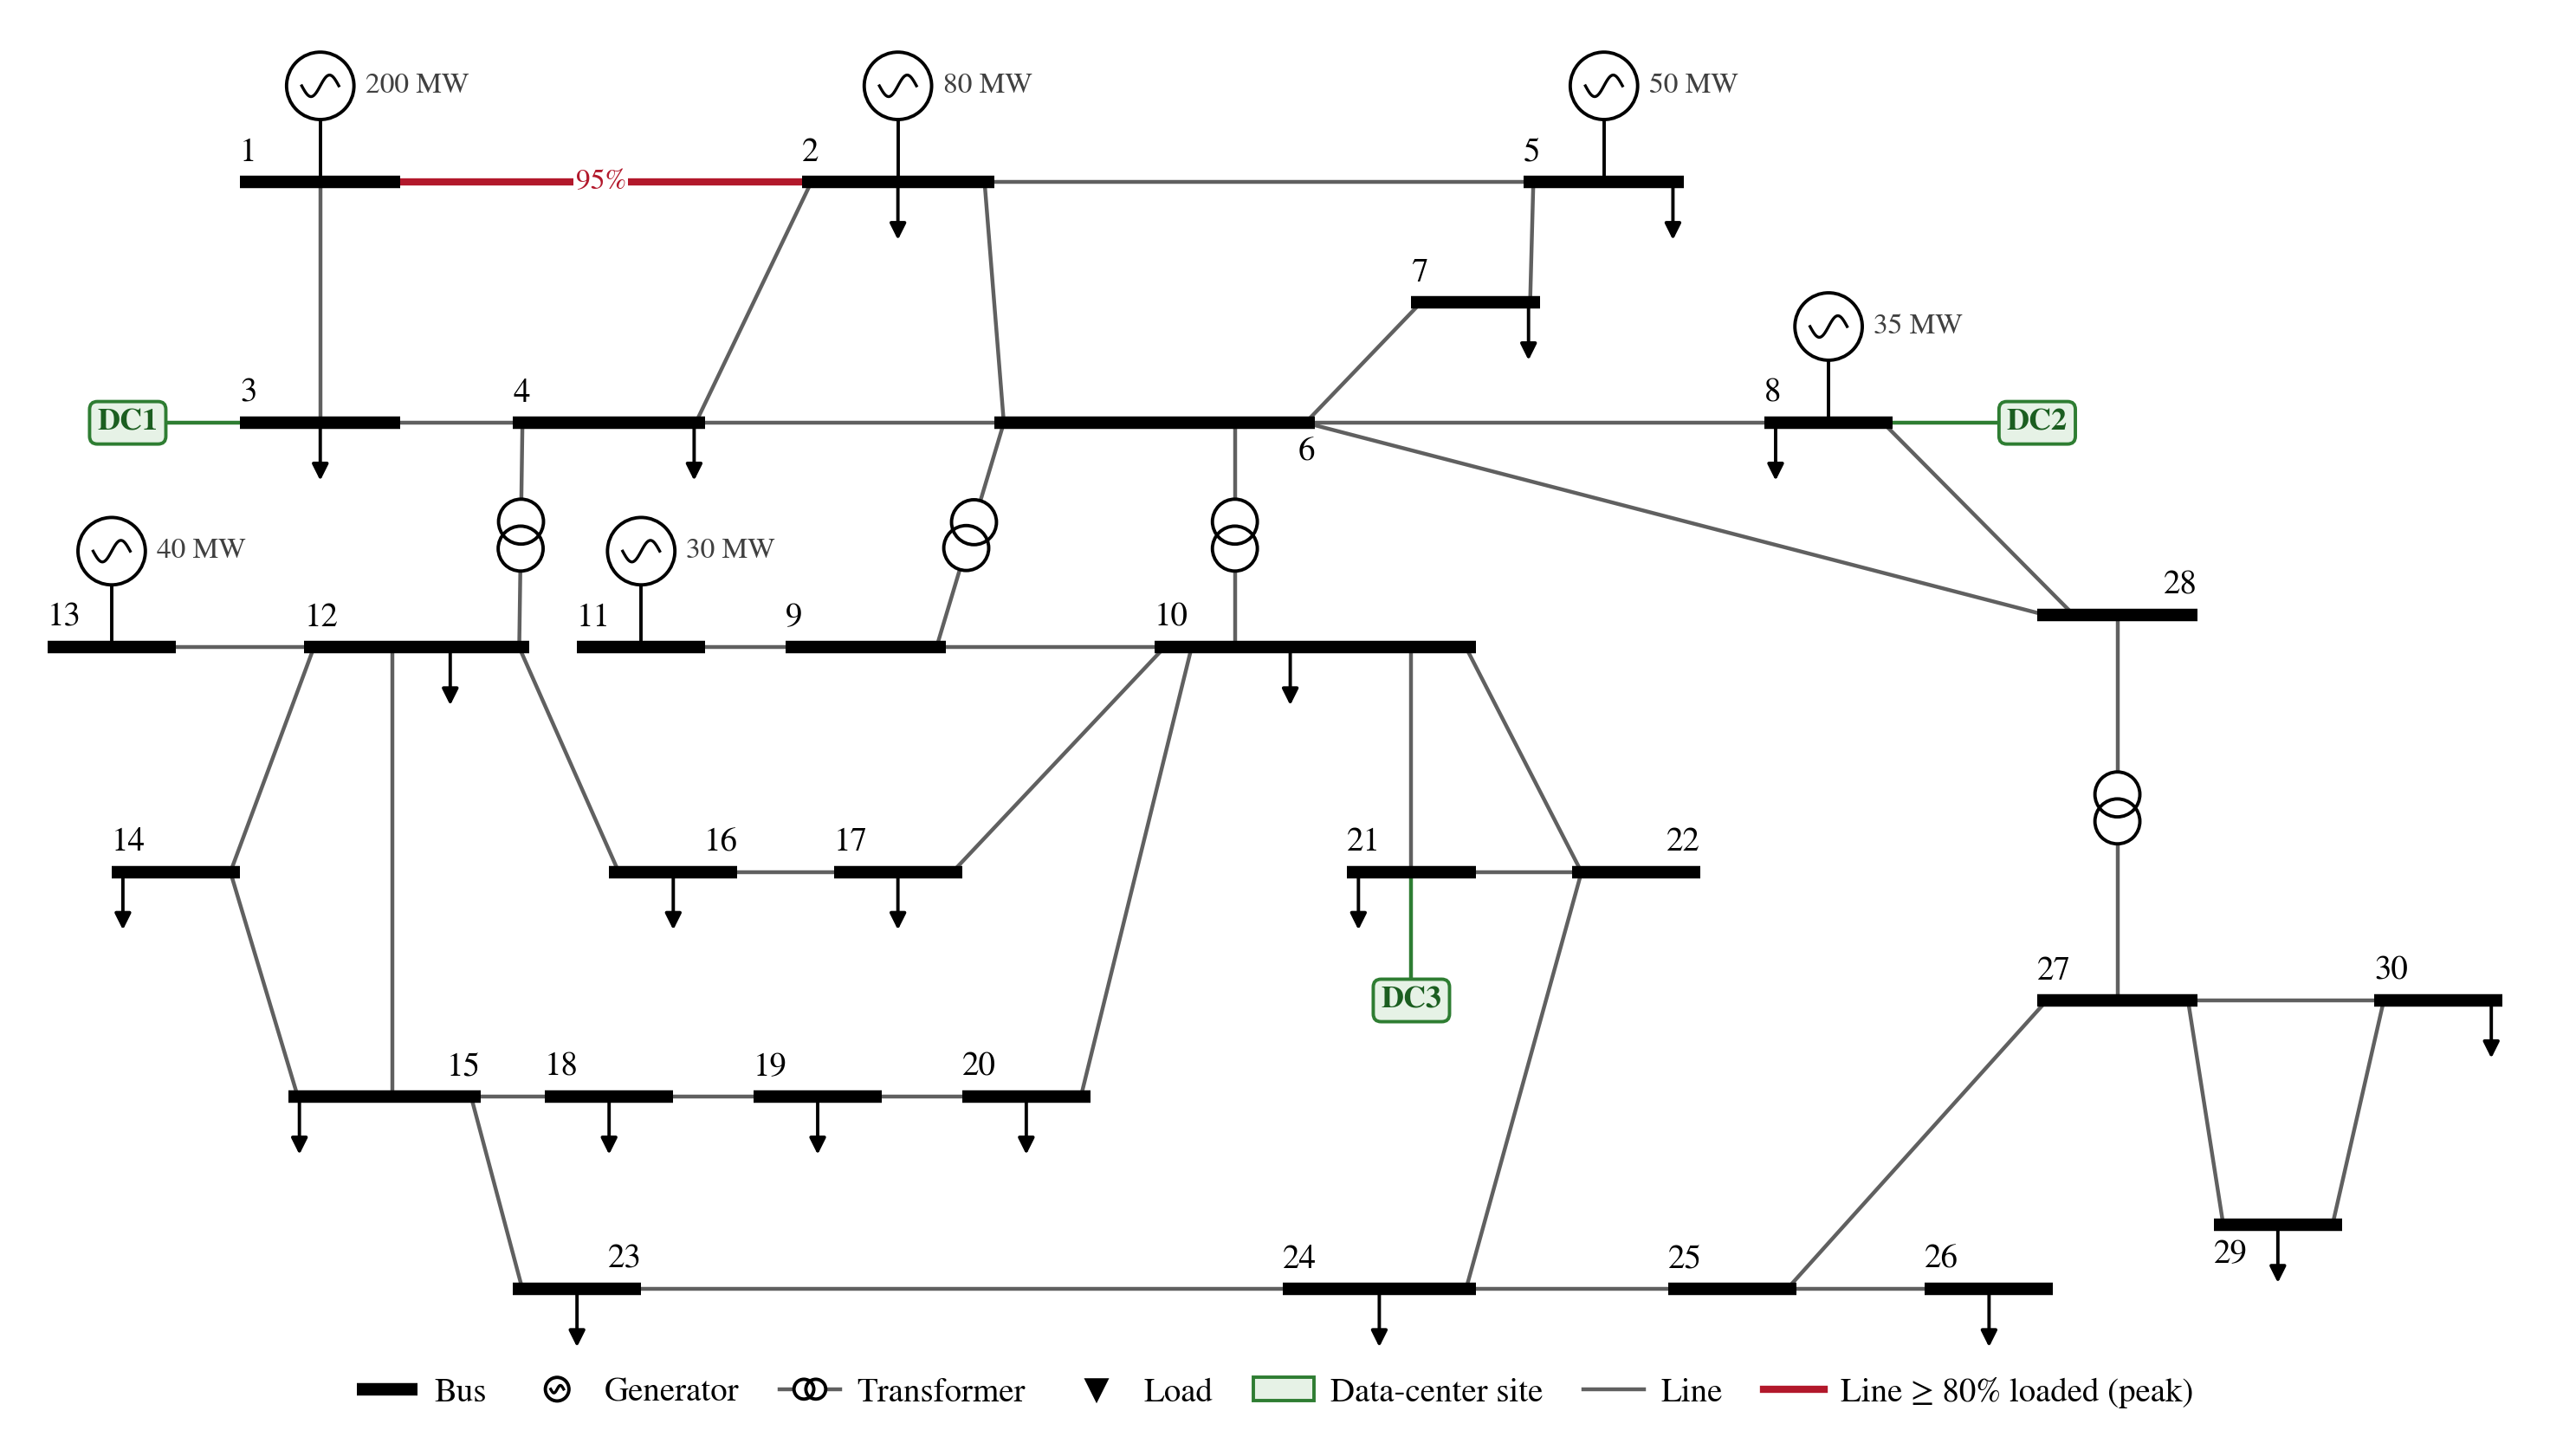

In [10]:
# %% 7. Paper figure: IEEE 30-bus one-line diagram (landscape, double column) ------------------
%config InlineBackend.figure_format = 'retina'
from collections import defaultdict
from matplotlib.patches import Circle, Patch
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerBase

# ---------------- style ----------------
FIG_W    = 7.16                    # inches: IEEE double column
FS_BUS   = 7.0                     # bus numbers / legend
FS_SMALL = 6.0                     # capacities, loadings, DC labels
LW_BUS, LW_LINE, LW_HOT = 2.6, 0.8, 1.5
INK, GREY, HOTC = 'k', '#606060', '#b2182b'
DC_FC, DC_EC, DC_TXT = '#e6f2e6', '#2e7d32', '#1b5e20'
HOT   = 0.8                        # highlight lines loaded at/above this share at peak
LEG_H = 0.28                       # inches reserved for the one-row legend
plt.rcParams.update({'font.family': 'serif',
                     'font.serif': ['Times New Roman', 'Times', 'Nimbus Roman', 'STIXGeneral', 'DejaVu Serif'],
                     'mathtext.fontset': 'stix', 'pdf.fonttype': 42, 'ps.fonttype': 42,
                     'figure.dpi': 200, 'savefig.dpi': 600})

# ---------------- layout (classic IEEE 30-bus arrangement, stretched horizontally) ----------------
POS = {1:(0.0, 4.5),   2:(3.6, 4.5),   5:(8.0, 4.5),
       7:(7.2, 3.75),
       3:(0.0, 3.0),   4:(1.8, 3.0),   6:(5.2, 3.0),   8:(9.4, 3.0),
       28:(11.2, 1.8),
       13:(-1.3, 1.6), 12:(0.6, 1.6),  11:(2.0, 1.6),  9:(3.4, 1.6),  10:(6.2, 1.6),
       14:(-0.9, 0.2), 16:(2.2, 0.2),  17:(3.6, 0.2),  21:(6.8, 0.2), 22:(8.2, 0.2),
       27:(11.2, -0.6), 30:(13.2, -0.6),
       15:(0.4, -1.2), 18:(1.8, -1.2), 19:(3.1, -1.2), 20:(4.4, -1.2),
       29:(12.2, -2.0),
       23:(1.6, -2.4), 24:(6.6, -2.4), 25:(8.8, -2.4), 26:(10.4, -2.4)}
H0   = 0.4                                             # default half-length of a bus bar
HALF = {1:.5, 2:.6, 3:.5, 4:.6, 5:.5, 6:1.0, 9:.5, 10:1.0, 12:.7, 15:.6, 24:.6, 27:.5, 28:.5}
GEN_DIR   = {}                                         # 'up' (default) / 'down' / 'left' / 'right'
DC_OFFSET = {3: (-1.2, 0.0), 8: (1.3, 0.0), 21: (0.0, -0.8)}    # data-center box offset from bus
DC_LABEL  = [f'DC{s + 1}' for s in range(len(SITE_BUS))]         # 1-based for the paper
LABEL_FIX = {}                                         # force a bus-number spot, e.g. {6: 'br'}

# transformer branches of the original IEEE case (the AS data may carry no tap ratios)
XFMR = {(6, 9), (6, 10), (4, 12), (28, 27)}
XFMR |= {(f, t) for f, t, tp in zip(F_BUS, T_BUS, br.TAP.values) if tp not in (0, 1)}
XFMR = {frozenset(p) for p in XFMR}

def bar(b):
    x, y = POS[b]; h = HALF.get(b, H0)
    return x - h, x + h, y

_lo = min(bar(b)[0] for b in POS); _hi = max(bar(b)[1] for b in POS)
UPI = (_hi - _lo + 0.6) / FIG_W                        # data units per inch (for text-box sizing)

def text_rect(x, y, s, fs, ha, va):
    hgt = fs / 72 * UPI; wid = 0.55 * hgt * len(s)
    x0 = {'left': x, 'right': x - wid, 'center': x - wid / 2}[ha]
    y0 = {'bottom': y, 'top': y - hgt, 'center': y - hgt / 2}[va]
    return x0, y0, x0 + wid, y0 + hgt

obs = []                                               # sampled points of everything drawn
def add_seg(p, q, step=0.04):
    n = max(2, int(np.hypot(q[0] - p[0], q[1] - p[1]) / step) + 1)
    obs.append(np.linspace(p, q, n))
def add_rect(x0, y0, x1, y1, step=0.05):
    gx, gy = np.meshgrid(np.arange(x0, x1 + step, step), np.arange(y0, y1 + step, step))
    obs.append(np.column_stack([gx.ravel(), gy.ravel()]))

# ---------------- line end points: project onto bars, then spread so ends never coincide ----------------
ends, groups = {}, defaultdict(list)
for l in range(nl):
    a, b = F_BUS[l], T_BUS[l]
    (al, ah, ay), (bl, bh, by) = bar(a), bar(b)
    xa, xb = POS[a][0], POS[b][0]
    if abs(ay - by) < 1e-6:                            # same row: connect facing bar ends
        ends[l, 0], ends[l, 1] = (ah, bl) if xb > xa else (al, bh)
        continue
    lo, hi = max(al, bl), min(ah, bh)
    da, db = ((lo + hi) / 2,) * 2 if lo < hi else (np.clip(xb, al, ah), np.clip(xa, bl, bh))
    dy = abs(by - ay)
    groups[a, 'up' if by > ay else 'dn'].append((da, (xb - xa) / dy, l, 0))
    groups[b, 'up' if ay > by else 'dn'].append((db, (xa - xb) / dy, l, 1))

GAP, MARGIN = 0.17, 0.06
for (b, side), items in groups.items():
    lo, hi, _ = bar(b); lo += MARGIN; hi -= MARGIN
    items.sort(key=lambda t: (t[0], t[1]))             # by position, then fan direction (no crossings)
    p = np.clip([t[0] for t in items], lo, hi).astype(float)
    g = min(GAP, (hi - lo) / max(len(p) - 1, 1))
    for i in range(1, len(p)):            p[i] = max(p[i], p[i - 1] + g)
    p[-1] = min(p[-1], hi)
    for i in range(len(p) - 2, -1, -1):   p[i] = min(p[i], p[i + 1] - g)
    for (_, _, l, w), x in zip(items, p): ends[l, w] = x

# ---------------- draw ----------------
loading = np.abs(F_opf[PK]) / RATE                     # peak-hour loading, share of rating
fig, ax = plt.subplots(figsize=(FIG_W, 4))
seg = {}

for l in range(nl):                                    # lines
    p, q = (ends[l, 0], POS[F_BUS[l]][1]), (ends[l, 1], POS[T_BUS[l]][1])
    seg[l] = (p, q)
    hot = loading[l] >= HOT
    ax.plot(*zip(p, q), color=HOTC if hot else GREY, lw=LW_HOT if hot else LW_LINE,
            solid_capstyle='round', zorder=1)
    add_seg(p, q)

R_X = 0.14                                             # transformers: two interlocking circles
for l in range(nl):
    if frozenset((F_BUS[l], T_BUS[l])) not in XFMR: continue
    (x0, y0), (x1, y1) = seg[l]
    L = np.hypot(x1 - x0, y1 - y0); ux, uy = (x1 - x0) / L, (y1 - y0) / L
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    centers = [(cx + s * 0.6 * R_X * ux, cy + s * 0.6 * R_X * uy) for s in (-1, 1)]
    for c in centers: ax.add_patch(Circle(c, R_X, fc='white', ec='none', zorder=3))
    for c in centers: ax.add_patch(Circle(c, R_X, fc='none', ec=INK, lw=0.7, zorder=4))
    add_rect(cx - 1.6 * R_X, cy - 1.6 * R_X, cx + 1.6 * R_X, cy + 1.6 * R_X)

for b in BUS_I:                                        # bus bars
    lo, hi, y = bar(b)
    ax.plot([lo, hi], [y, y], color=INK, lw=LW_BUS, solid_capstyle='butt', zorder=5)
    add_seg((lo, y), (hi, y))

R_G, DY_G = 0.21, 0.6                                  # generators: circle with a sine wave
for b in np.unique(GEN_BUS):
    x, y = POS[b]; h = HALF.get(b, H0); cap = pmax[GEN_BUS == b].sum()
    d = GEN_DIR.get(b, 'up')
    if   d == 'up':    gx, gy = x, y + DY_G;     stub = ((x, y), (x, gy - R_G))
    elif d == 'down':  gx, gy = x, y - DY_G;     stub = ((x, y), (x, gy + R_G))
    elif d == 'left':  gx, gy = x - h - DY_G, y; stub = ((x - h, y), (gx + R_G, y))
    else:              gx, gy = x + h + DY_G, y; stub = ((x + h, y), (gx - R_G, y))
    ax.plot(*zip(*stub), color=INK, lw=0.7, zorder=4); add_seg(*stub)
    ax.add_patch(Circle((gx, gy), R_G, fc='white', ec=INK, lw=0.7, zorder=6))
    t = np.linspace(-1, 1, 40)
    ax.plot(gx + 0.55 * R_G * t, gy + 0.32 * R_G * np.sin(np.pi * t), color=INK, lw=0.6, zorder=7)
    add_rect(gx - R_G, gy - R_G, gx + R_G, gy + R_G)
    s = f'{cap:.0f} MW'
    ax.text(gx + R_G + 0.07, gy, s, fontsize=FS_SMALL, color='#404040', ha='left', va='center', zorder=7)
    add_rect(*text_rect(gx + R_G + 0.07, gy, s, FS_SMALL, 'left', 'center'))

dc_down = defaultdict(list)                            # data-center sites
for s, b in enumerate(SITE_BUS):
    x, y = POS[b]; lo, hi, _ = bar(b); h = HALF.get(b, H0)
    dx, dy = DC_OFFSET.get(b, (0.0, -0.7))
    bx, by = x + dx, y + dy
    sx = hi if dx > h else lo if dx < -h else bx
    ax.plot([sx, bx], [y, by], color=DC_EC, lw=0.8, zorder=2); add_seg((sx, y), (bx, by))
    ax.text(bx, by, DC_LABEL[s], ha='center', va='center', fontsize=FS_SMALL + 0.5, color=DC_TXT,
            fontweight='bold', zorder=8,
            bbox=dict(boxstyle='round,pad=0.25', fc=DC_FC, ec=DC_EC, lw=0.7))
    x0, y0, x1, y1 = text_rect(bx, by, DC_LABEL[s], FS_SMALL + 0.5, 'center', 'center')
    add_rect(x0 - 0.1, y0 - 0.1, x1 + 0.1, y1 + 0.1)
    if dy < 0: dc_down[b].append(sx)

LOAD_LEN = 0.36                                        # loads: arrow below the bar, at the freest spot
for i, b in enumerate(BUS_I):
    if pd0[i] <= 0: continue
    lo, hi, y = bar(b); x = POS[b][0]
    taken = [ends[l, w] for _, _, l, w in groups.get((b, 'dn'), [])] + dc_down[b]
    cand = np.linspace(lo + 0.07, hi - 0.07, 13)
    score = [min([abs(c - t) for t in taken], default=9.0) - 0.02 * abs(c - x) for c in cand]
    c = cand[int(np.argmax(score))]
    ax.annotate('', xy=(c, y - LOAD_LEN), xytext=(c, y), zorder=4,
                arrowprops=dict(arrowstyle='-|>', mutation_scale=7, lw=0.7, color=INK, shrinkA=0, shrinkB=0))
    add_seg((c, y), (c, y - LOAD_LEN))

for l in range(nl):                                    # loading labels on hot lines
    if loading[l] < HOT: continue
    (x0, y0), (x1, y1) = seg[l]
    t = 0.27 if frozenset((F_BUS[l], T_BUS[l])) in XFMR else 0.5
    tx, ty = x0 + t * (x1 - x0), y0 + t * (y1 - y0)
    s = f'{loading[l]:.0%}'
    ax.text(tx, ty, s, fontsize=FS_SMALL, color=HOTC, ha='center', va='center', zorder=9,
            bbox=dict(fc='white', ec='none', pad=0.4))
    add_rect(*text_rect(tx, ty, s, FS_SMALL, 'center', 'center'))

D, PREF = 0.09, ['al', 'ar', 'bl', 'br', 'l', 'r']    # bus numbers: least-cluttered of six spots
for b in BUS_I:
    lo, hi, y = bar(b); s = str(b)
    opts = {'al': (lo, y + D, 'left', 'bottom'), 'ar': (hi, y + D, 'right', 'bottom'),
            'bl': (lo, y - D, 'left', 'top'),    'br': (hi, y - D, 'right', 'top'),
            'l':  (lo - D, y, 'right', 'center'), 'r': (hi + D, y, 'left', 'center')}
    P = np.vstack(obs)
    def hits(k):
        x0, y0, x1, y1 = text_rect(opts[k][0], opts[k][1], s, FS_BUS, opts[k][2], opts[k][3])
        return np.sum((P[:, 0] > x0 - .03) & (P[:, 0] < x1 + .03) & (P[:, 1] > y0 - .03) & (P[:, 1] < y1 + .03))
    k = LABEL_FIX.get(b) or min(PREF, key=lambda k: (hits(k), PREF.index(k)))
    x, yy, ha, va = opts[k]
    ax.text(x, yy, s, fontsize=FS_BUS, ha=ha, va=va, zorder=9)
    add_rect(*text_rect(x, yy, s, FS_BUS, ha, va))

# ---------------- legend (one row) ----------------
class _Gen: pass
class _Xf:  pass
class HGen(HandlerBase):
    def create_artists(self, legend, orig, x0, y0, w, h, fs, trans):
        r, cx, cy = 0.5 * h, x0 + w / 2, y0 + h / 2; t = np.linspace(-1, 1, 30)
        return [Circle((cx, cy), r, fc='white', ec=INK, lw=0.7, transform=trans),
                Line2D(cx + 0.55 * r * t, cy + 0.32 * r * np.sin(np.pi * t), color=INK, lw=0.6, transform=trans)]
class HXf(HandlerBase):
    def create_artists(self, legend, orig, x0, y0, w, h, fs, trans):
        r, cx, cy = 0.42 * h, x0 + w / 2, y0 + h / 2
        out = [Line2D([x0, x0 + w], [cy, cy], color=GREY, lw=LW_LINE, transform=trans)]
        out += [Circle((cx + s * 0.6 * r, cy), r, fc='white', ec='none', transform=trans) for s in (-1, 1)]
        out += [Circle((cx + s * 0.6 * r, cy), r, fc='none', ec=INK, lw=0.7, transform=trans) for s in (-1, 1)]
        return out

handles = [Line2D([], [], color=INK, lw=LW_BUS, solid_capstyle='butt'), _Gen(), _Xf(),
           Line2D([], [], marker='v', ls='', color=INK, ms=3.5),
           Patch(fc=DC_FC, ec=DC_EC, lw=0.7),
           Line2D([], [], color=GREY, lw=LW_LINE), Line2D([], [], color=HOTC, lw=LW_HOT)]
labels = ['Bus', 'Generator', 'Transformer', 'Load', 'Data-center site', 'Line',
          f'Line ≥ {HOT:.0%} loaded (peak)']
ax.legend(handles, labels, handler_map={_Gen: HGen(), _Xf: HXf()}, loc='upper center',
          bbox_to_anchor=(0.5, 0.0), ncol=len(labels), frameon=False, fontsize=FS_BUS,
          handlelength=1.8, handletextpad=0.5, columnspacing=1.2, borderaxespad=0.1)

# ---------------- frame to content, size the figure ----------------
P = np.vstack(obs); m = 0.08
x0, x1 = P[:, 0].min() - m, P[:, 0].max() + m
y0, y1 = P[:, 1].min() - m, P[:, 1].max() + m
ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect('equal'); ax.axis('off')
H = FIG_W * (y1 - y0) / (x1 - x0) + LEG_H
fig.set_size_inches(FIG_W, H); ax.set_position([0, LEG_H / H, 1, 1 - LEG_H / H])
plt.savefig('fig_ieee30.pdf', bbox_inches='tight', pad_inches=0.01)            # vector, for LaTeX
plt.savefig('fig_ieee30.png', bbox_inches='tight', pad_inches=0.01, dpi=600)   # raster, for slides/Word
plt.show()